# 01 — EDA de regresión (HISTORICO_SUERTES)

**Objetivo de esta sección:** diagnóstico de valores faltantes sobre las predictoras seleccionadas
y verificación de la pregunta abierta *"¿los ceros en lluvias son sin dato?"*.

> Este notebook **no transforma ni imputa** nada: diagnostica y documenta las decisiones.
> La imputación y el tratamiento de outliers se
> implementarán dentro de un `Pipeline` con `fit()` sobre `X_train` (los estadísticos se calculan solo con entrenamiento) después del
> split 80/20. Todo lo que sigue son conteos descriptivos de la *calidad* del dato (no estadísticos
> de imputación), por lo que no filtran información del test.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src.datos import (LLUVIAS_VENTANA, PREDICTORAS_REGRESION, PREDICTORAS_SOLO_SAC,
                       RUTA_HISTORICO, TARGETS_REGRESION, cargar_historico)

FIG_DIR = RAIZ / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)

## 1. Carga y filtro de semilla

In [2]:
n_raw = len(pd.read_csv(RUTA_HISTORICO, encoding="utf-8-sig", usecols=["Período"]))
df = cargar_historico()
print(f"Filas crudas: {n_raw:,} | tras excluir semilla: {len(df):,} | excluidas: {n_raw - len(df)}")
assert n_raw - len(df) == 294

Filas crudas: 21,027 | tras excluir semilla: 20,733 | excluidas: 294


## 2. % de nulos sobre las predictoras seleccionadas

Además del `NaN` explícito se reporta el % de **ceros**, porque en este dataset varios "sin dato"
vienen codificados como 0 (ver secciones 3–5). La columna `sin_dato_efectivo` suma ambos solo
cuando el 0 está verificado como "sin dato" (lluvias, `DDUlt.Riego`, `Sac.Caña Precosecha`).

In [3]:
CERO_ES_SIN_DATO = set(LLUVIAS_VENTANA) | {"DDUlt.Riego", "Sac.Caña Precosecha"}
cols = PREDICTORAS_REGRESION + PREDICTORAS_SOLO_SAC + TARGETS_REGRESION

def resumen_nulos(d, cols):
    filas = []
    for c in cols:
        s = d[c]
        nulos = s.isna().mean() * 100
        ceros = (pd.to_numeric(s, errors="coerce") == 0).mean() * 100 if s.dtype.kind in "if" else np.nan
        efectivo = nulos + (ceros if c in CERO_ES_SIN_DATO else 0)
        filas.append({"variable": c, "dtype": str(s.dtype), "pct_nulos": nulos,
                      "pct_ceros": ceros, "sin_dato_efectivo": efectivo, "n_unicos": s.nunique()})
    return pd.DataFrame(filas).set_index("variable").round(1)

tabla_nulos = resumen_nulos(df, cols)
tabla_nulos.sort_values("sin_dato_efectivo", ascending=False)

,dtype,pct_nulos,pct_ceros,sin_dato_efectivo,n_unicos
variable,,,,,
DDUlt.Riego,int64,0.0,60.4,60.4,427
Sac.Caña Precosecha,float64,5.3,50.6,55.9,637
Lluvias (2 Meses Ant.),float64,0.0,48.5,48.5,493
Luvias 9 -FC,float64,0.0,46.0,46.0,1097
Producto,str,45.8,NaN,45.8,18
Semanas mad.,float64,45.8,0.0,45.8,470
Lluvias seis a nueve,float64,0.0,45.2,45.2,638
Lluvias 0 -3,float64,0.0,44.8,44.8,641
Lluvias tres a seis,float64,0.0,44.8,44.8,668


Lectura rápida:
- **Sin nulos:** `Edad Ult Cos`, `Cod.Estado #`, `Variedad`, `Zona`, `Dist Km`, `T.Corte`,
  `Tenencia`, `Cultivo`, `Período`, `TCH`. (`Cod.Estado #` = 0 es *Plantilla*, un valor legítimo.)
- **Nulos explícitos relevantes:** `Suelo` (18%), bloque madurante (`Producto`, `Semanas mad.`, 46%).
- **Nulos ocultos como 0:** lluvias por ventana (45–49%), riego (60%), `Sac.Caña Precosecha` (51%).

### 2.1 `Suelo`: ¿el nulo es aleatorio?

In [4]:
df.groupby("Zona")["Suelo"].apply(lambda s: s.isna().mean()).round(2).to_frame("pct_nulo_suelo").join(
    df["Zona"].value_counts().rename("n"))

,pct_nulo_suelo,n
Zona,,
IC07,1.00,1
IP01,0.09,2243
IP02,0.03,1576
IP03,0.17,5168
IP05,0.31,7741
IP06,0.05,3990
ip05,1.00,14


### 2.2 Bloque madurante: consistencia `Producto` ↔ `Dosis Madurante` ↔ `Semanas mad.`

In [5]:
sin_prod = df["Producto"].isna()
display(pd.crosstab(sin_prod.rename("Producto vacío"),
                    [df["Semanas mad."].isna().rename("Semanas NaN"), df["Fec.Madur."].isna().rename("Fec.Madur. NaN")]))
dosis_cat = np.select([df["Dosis Madurante"].isna(), df["Dosis Madurante"] == 0], ["NaN", "0"], ">0")
pd.crosstab(sin_prod.map({True: "Producto vacío", False: "Producto informado"}), dosis_cat)

Semanas NaN,False,True
Fec.Madur. NaN,False,True
Producto vacío,,
False,11235,0
True,3,9495


col_0,0,>0,NaN
Producto,,,
Producto informado,24,11211,0
Producto vacío,9399,3,96


- Los 96 `Dosis Madurante = NaN` tienen `Producto` vacío → son "no aplicado", igual que el 0.
- `Semanas mad.` y `Fec.Madur.` están vacías exactamente en las mismas filas, que coinciden con
  `Producto` vacío salvo en 3 casos.
- Inconsistencias menores que se revisan en el bloque de consistencia/outliers: 24 filas tienen
  producto pero dosis 0, y 3 filas no tienen producto pero sí dosis > 0 y fecha de maduración
  (lo más probable es que falte capturar `Producto`).

In [6]:
df["Semanas mad."].describe().round(1)

count    11238.0
mean         9.6
std          5.6
min         -2.0
25%          6.6
50%          8.6
75%         11.1
max         96.3
Name: Semanas mad., dtype: float64

## 3. Verificación: ¿los ceros en lluvias son "sin dato"?

Pregunta abierta del EDA. Se contrastan seis evidencias independientes.

In [7]:
LL_CICLO = "Lluvias Ciclo"
VENT4 = LLUVIAS_VENTANA[1:]  # 0-3, 3-6, 6-9, 9-FC (suman el ciclo)
cero = df[LLUVIAS_VENTANA + [LL_CICLO]] == 0
ciclo0 = cero[LL_CICLO]
anio = df["Período"] // 100
print(f"Lluvias Ciclo == 0: {ciclo0.mean():.1%} de las filas")

Lluvias Ciclo == 0: 37.3% de las filas


**3.1 Coherencia interna:** si el ciclo es 0, ¿lo son todas las ventanas? ¿Las ventanas suman el ciclo?

In [8]:
print("Ciclo == 0 y alguna ventana > 0:", (ciclo0 & ~cero[VENT4].all(axis=1)).sum())
dif = (df.loc[~ciclo0, VENT4].sum(axis=1) - df.loc[~ciclo0, LL_CICLO]).abs()
print("|suma ventanas − ciclo| (ciclo > 0):", dif.describe()[["50%", "75%", "max"]].to_dict())

Ciclo == 0 y alguna ventana > 0: 0
|suma ventanas − ciclo| (ciclo > 0): {'50%': 0.0, '75%': 0.0, 'max': 50.0}


**3.2 Plausibilidad física:** ¿qué tan largo es el ciclo de las filas con 0 mm acumulados?

In [9]:
df.loc[ciclo0, "Edad Ult Cos"].describe().round(1)

count    7728.0
mean       13.0
std         2.1
min         6.0
25%        12.0
50%        12.6
75%        13.9
max        78.2
Name: Edad Ult Cos, dtype: float64

**3.3 Contraste con fuente externa (Cenicaña).** Las variables climáticas Cenicaña están descartadas
como predictoras (78% nulos), pero donde existen sirven de testigo independiente.

In [10]:
con_cen = df["Precipitacion Ciclo"].notna()
print("Precipitación Cenicaña (ciclo) donde Lluvias Ciclo == 0:")
print(df.loc[con_cen & ciclo0, "Precipitacion Ciclo"].describe().round(0).to_dict())

m03 = df["Precipitacion 0_3"].notna() & ~ciclo0
print("\nPrecipitación Cenicaña (0-3) donde Lluvias 0-3 == 0 pero el ciclo > 0:")
print(df.loc[m03 & cero["Lluvias 0 -3"], "Precipitacion 0_3"].describe().round(0).to_dict())
pos = m03 & ~cero["Lluvias 0 -3"]
print("\nCorrelación Lluvias 0-3 vs Precipitación Cenicaña 0-3 (ambas > 0):",
      round(df.loc[pos, ["Lluvias 0 -3", "Precipitacion 0_3"]].corr().iloc[0, 1], 2))

Precipitación Cenicaña (ciclo) donde Lluvias Ciclo == 0:
{'count': 1633.0, 'mean': 1170.0, 'std': 348.0, 'min': 29.0, '25%': 925.0, '50%': 1143.0, '75%': 1310.0, 'max': 3034.0}

Precipitación Cenicaña (0-3) donde Lluvias 0-3 == 0 pero el ciclo > 0:
{'count': 100.0, 'mean': 273.0, 'std': 103.0, 'min': 78.0, '25%': 194.0, '50%': 261.0, '75%': 358.0, 'max': 510.0}

Correlación Lluvias 0-3 vs Precipitación Cenicaña 0-3 (ambas > 0): 0.65


**3.4 Patrón de ceros parciales** (ciclo > 0). Si fueran sequías reales aparecerían en ventanas
sueltas; si es registro truncado, aparecen en bloques contiguos en los extremos del ciclo.
Código: un dígito por ventana (0-3, 3-6, 6-9, 9-FC), `1` = cero.

In [11]:
patron = cero.loc[~ciclo0, VENT4].astype(int).astype(str).agg("".join, axis=1)
patron.value_counts().head(10).to_frame("n")

,n
0000,9624
0001,624
0011,541
0111,490
1100,486
1110,466
1000,458
1001,75
0010,72
0100,45


**3.5 ¿Es aleatorio (MAR)?** Distribución de los ceros por año, Tenencia y hacienda, y co-ocurrencia con riego = 0.

In [12]:
por_tenencia = ciclo0.groupby(df["Tenencia"]).agg(["mean", "size"]).rename(columns={"mean": "pct_cero", "size": "n"})
por_anio = ciclo0.groupby(anio).mean().rename("pct_cero")
display(por_tenencia.round(2), por_anio.round(2).to_frame())

h = ciclo0.groupby(df["Hacienda"]).mean()
print(f"Haciendas: {len(h)} | siempre 0: {(h == 1).sum()} | nunca 0: {(h == 0).sum()} | mixtas: {((h > 0) & (h < 1)).sum()}")
print("\nCo-ocurrencia con riego = 0 (% del total):")
pd.crosstab(df["M3 Riego"] == 0, ciclo0, normalize="all", rownames=["M3 Riego == 0"],
            colnames=["Lluvias Ciclo == 0"]).round(2)

,pct_cero,n
Tenencia,,
11.0,0.00,2824
28.0,0.00,323
31.0,0.02,3905
51.0,0.52,9953
81.0,0.70,3528
82.0,1.00,13
91.0,0.01,186


,pct_cero
Período,
2017,0.32
2018,0.32
2019,0.43
2020,0.39
2021,0.27
2022,0.28
2023,0.50
2024,0.53


Haciendas: 926 | siempre 0: 500 | nunca 0: 184 | mixtas: 242

Co-ocurrencia con riego = 0 (% del total):


Lluvias Ciclo == 0,False,True
M3 Riego == 0,,
False,0.39,0.01
True,0.24,0.36


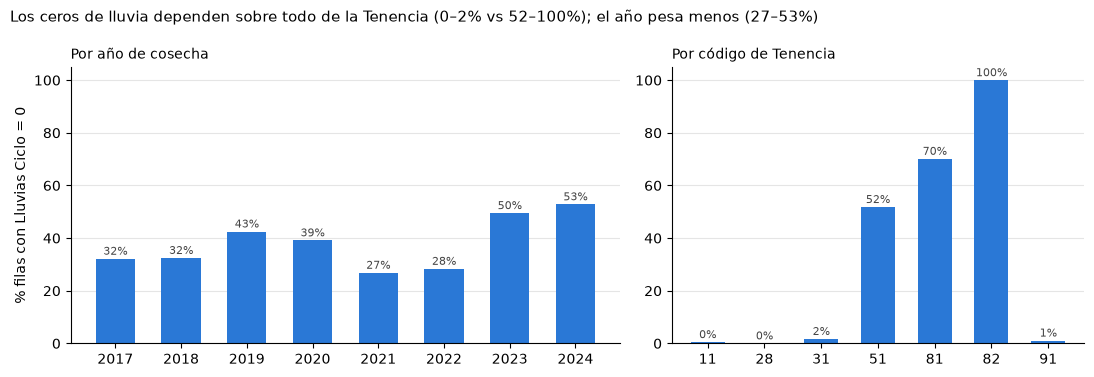

In [13]:
AZUL = "#2a78d6"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [8, 6]})
for ax, serie, titulo in [
    (axes[0], por_anio, "Por año de cosecha"),
    (axes[1], por_tenencia["pct_cero"].rename(lambda x: str(int(x))), "Por código de Tenencia"),
]:
    x = serie.index.astype(str)
    ax.bar(x, serie.values * 100, color=AZUL, width=0.6)
    for xi, v in zip(x, serie.values):
        ax.text(xi, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=8, color="#444")
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.set_ylim(0, 105)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("% filas con Lluvias Ciclo = 0")
fig.suptitle("Los ceros de lluvia dependen sobre todo de la Tenencia (0–2% vs 52–100%); el año pesa menos (27–53%)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_reg_lluvia_ceros_anio_tenencia.png", dpi=150, bbox_inches="tight")
plt.show()

**3.6 ¿El vacío tiene señal propia?**

In [14]:
df.groupby(ciclo0.rename("Lluvias Ciclo == 0"))[["TCH", "%Sac.Caña", "Edad Ult Cos"]].median().round(2)

,TCH,%Sac.Caña,Edad Ult Cos
Lluvias Ciclo == 0,,,
False,133.00,12.38,12.70
True,124.31,12.36,12.65


### Conclusión 3 — **Confirmado: 0 en lluvias = "sin dato"**

1. Ciclo = 0 ⇒ las 4 ventanas = 0, sin excepción; cuando hay dato, las ventanas suman el ciclo.
2. Las filas con 0 mm tienen ciclos de ~12.7 meses: un año sin lluvia en el Valle del Cauca no es plausible.
3. Donde existe precipitación Cenicaña, las filas con 0 registran mediana ~1 140 mm de ciclo
   (mín. 29) y ~260 mm en 0-3 (mín. 78): **no se observa ningún 0 real**.
4. Los ceros parciales forman bloques contiguos en los extremos del ciclo → registro truncado.
5. **No es MAR**: se concentra en Tenencia 51 y 81 (vs. <2% en 11/28/31), en haciendas que nunca
   reportan, y coincide casi siempre con riego = 0 → ausencia de registro de campo del predio.
6. El grupo sin dato tiene TCH mediano más bajo (124 vs 133): el indicador de vacío porta señal.

**Regla:** todo 0 en cualquier ventana de lluvia se trata como `NaN`.

## 4. Riego: `M3 Riego`, `DDUlt.Riego`

In [15]:
riego0 = df["M3 Riego"] == 0
display(pd.crosstab(riego0, df["Ult.Riego"].isna(), rownames=["M3 Riego == 0"], colnames=["Ult.Riego NaN"]))
display(pd.crosstab(riego0, df["DDUlt.Riego"] == 0, rownames=["M3 Riego == 0"], colnames=["DDUlt.Riego == 0"]))
riego0.groupby(df["Tenencia"]).mean().round(2).to_frame("pct_riego_0")

Ult.Riego NaN,False,True
M3 Riego == 0,,
False,8210,0
True,0,12523


DDUlt.Riego == 0,False,True
M3 Riego == 0,,
False,8201,9
True,0,12523


,pct_riego_0
Tenencia,
11.0,0.11
28.0,0.12
31.0,0.10
51.0,0.83
81.0,0.96
82.0,1.00
91.0,0.67


`M3 Riego = 0` ⇔ `Ult.Riego` vacío ⇔ `DDUlt.Riego = 0` (coincidencia exacta, 12 523 filas). El patrón
por Tenencia replica el de lluvias. No se puede distinguir "no se regó" de "no hay registro"
→ se documenta como limitación. `DDUlt.Riego = 0` sin riego registrado es incoherente ("0 días desde
un riego que no existe"), así que ahí el 0 sí es "sin dato".

## 5. `Sac.Caña Precosecha` (solo para %Sac)

In [16]:
pre = df["Sac.Caña Precosecha"]
print("Valores > 0:", pre[pre > 0].describe().round(2).to_dict())
pd.DataFrame({"pct_NaN": pre.isna().groupby(anio).mean(),
              "pct_cero": (pre == 0).groupby(anio).mean(),
              "n": anio.value_counts().sort_index()}).round(2)

Valores > 0: {'count': 9150.0, 'mean': 16.98, 'std': 1.3, 'min': 8.94, '25%': 16.37, '50%': 17.07, '75%': 17.67, 'max': 44.78}


,pct_NaN,pct_cero,n
Período,,,
2017,0.04,0.17,2487
2018,0.05,0.16,2847
2019,0.06,0.14,2807
2020,0.09,0.10,2861
2021,0.06,0.79,2485
2022,0.04,0.95,2883
2023,0.04,0.96,2959
2024,0.02,0.98,1404


Una sacarosa del 0% es físicamente imposible (los valores > 0 tienen un p25–p75 de 16.4–17.7), así que
el 0 significa "no se muestreó". El vacío es estructural: entre el 95% y el 98% de los registros de
2022–2024 no tienen dato.

**Decisión aprobada:** la comparación del modelo de %Sac "con / sin" precosecha se
hace solo sobre el subconjunto con dato real (2017–2021). Ojo: en 2021 ya falta el 79%, así que
el subconjunto queda formado en la práctica por 2017–2020 más una fracción de 2021. Se documenta que su R² **no es
directamente comparable** con el del modelo principal.

## 6. Estrategia de imputación (no aplicada todavía)

Todo se implementa dentro de `Pipeline`/`ColumnTransformer`, con `fit()` solo sobre `X_train`
(regla del proyecto: estadísticos solo con entrenamiento; las reglas de negocio de referencia del curso (RN), §Imputación: *"Siempre: fit() del imputador/escalador solo
sobre X_train"*).

| Variable | Sin dato efectivo | Estrategia | Justificación (RN = reglas de negocio de referencia del curso) |
|---|---|---|---|
| `Producto` | 45.8% | Categoría explícita **"No aplicado"** | RN §Imputación: *"`Producto`, `Dosis Madurante`, `Semanas mad.` en blanco/0 = no se aplicó madurante… Crear categoría explícita, no imputar con la media"*. |
| `Dosis Madurante` | 0.5% NaN | NaN → **0** (los 96 NaN tienen `Producto` vacío); el 0 existente se mantiene | Ídem RN §Imputación. |
| `Semanas mad.` | 45.8% | NaN → **0** + flag **`madurada`** (el flag evita que el 0 se lea como "cosecha inmediata") | Ídem; el flag `madurada` ya está en las predictoras. Valores −2 y 96 se tratan en el bloque de outliers. |
| `Suelo` | 18.1% | Categoría **"Desconocido"** (ya decidido); no moda | RN §Unidades: taxonomía Cenicaña, no "corregir" categorías. El nulo es MNAR por zona (IP05 31%). |
| Lluvias ×5 ventanas | 45–49% (0 = sin dato) | 0 → NaN + **`MissingIndicator`** (`tiene_dato_lluvia`) + **mediana por Zona × mes_cosecha** calculada en train (fallback: mediana de Zona) | RN §Imputación (climáticas): *"No es missing-at-random. No imputar con media global… imputar por zona+mes documentando que es aproximación"*. Consigna: *"imputar por la media de una zona o periodo similar"*. El flag conserva la señal del vacío (§3.6). |
| `M3 Riego` | 60.4% | Mantener el 0 + flag **`tiene_registro_riego`** | RN §Imputación: *"el vacío puede ser información, no ruido"*. No se puede separar "no regado" de "sin registro" → limitación documentada. |
| `DDUlt.Riego` | 60.4% (0 = sin dato) | 0 → NaN + **mediana de train**; el flag `tiene_registro_riego` cubre el vacío | Ídem; el 0 es incoherente sin riego. |
| `Sac.Caña Precosecha` | 55.9% | 0 → NaN, **sin imputar**; variante "con precosecha" solo sobre el subconjunto con dato (2017–2021) | Imputar un proxy casi directo del target introduciría un valor sintético muy correlacionado con %Sac (RN §Leakage: R² altos sospechosos). |
| `%Sac.Caña` (target) | 0.8% | Se eliminan esas filas en el modelo de %Sac; el target no se imputa | — |

**Nota sobre colinealidad:** `tiene_dato_lluvia` y `tiene_registro_riego` coinciden en la mayoría de
las filas (§3.5). En el modelo lineal se revisa el VIF entre ambos flags y `Tenencia` antes de
interpretar coeficientes (RN §Validación: *"VIF sigue siendo relevante… si el objetivo es interpretar"*).

## 7. Escala de la lluvia: ¿a qué se refiere el rango "normal 180–300, atípico ~1000"?

las reglas de negocio de referencia del curso (RN) (§Outliers) y la guía del curso dicen: *"En variables climáticas (ej. lluvias anuales), un valor
como ~1000 frente a un rango típico de 180–300 sí es un atípico genuino"*. Pero la mediana de
`Lluvias Ciclo` es ~800 mm. Antes del bloque de outliers hay que saber a qué escala aplica la regla.
Se usan solo las filas con dato (0 = sin dato, §3).

In [17]:
con = df[df[LL_CICLO] > 0]
print("Meses cubiertos por Lluvias Ciclo (Edad Ult Cos):", con["Edad Ult Cos"].describe()[["mean", "25%", "50%", "75%"]].round(1).to_dict())
mm_mes = con[LL_CICLO] / con["Edad Ult Cos"]
print(f"Tasa mm/mes (mediana): {mm_mes.median():.1f} | ciclo anualizado (mediana): {(mm_mes * 12).median():.0f} mm")
print(f"Cenicaña, ciclo anualizado (mediana): {(df['Precipitacion Ciclo'] / df['Edad Ult Cos'] * 12).median():.0f} mm")

def escala(s):
    s = s[s > 0]
    return pd.Series({"p25": s.quantile(.25), "mediana": s.median(), "p75": s.quantile(.75), "p95": s.quantile(.95),
                      "%_en_180_300": s.between(180, 300).mean() * 100, "%_>=900": (s >= 900).mean() * 100})

pd.DataFrame({c: escala(con[c]) for c in LLUVIAS_VENTANA + [LL_CICLO]}).T.round(1)

Meses cubiertos por Lluvias Ciclo (Edad Ult Cos): {'mean': 13.1, '25%': 12.0, '50%': 12.7, '75%': 13.9}
Tasa mm/mes (mediana): 64.2 | ciclo anualizado (mediana): 770 mm
Cenicaña, ciclo anualizado (mediana): 1138 mm


,p25,mediana,p75,p95,%_en_180_300,%_>=900
Lluvias (2 Meses Ant.),76.0,126.5,193.0,309.0,23.0,0.0
Lluvias 0 -3,118.0,204.0,299.0,441.0,32.7,0.1
Lluvias tres a seis,120.0,195.0,288.0,451.0,33.0,0.1
Lluvias seis a nueve,119.0,197.0,287.0,438.0,33.1,0.1
Luvias 9 -FC,145.0,248.0,413.0,768.5,25.3,2.7
Lluvias Ciclo,518.0,812.0,1111.0,1651.0,5.2,42.1


Testigo adicional: la regla probablemente se escribió pensando en la variable `lluvias` de
**BD_IPSA_1940** (diccionario de variables del dataset: *"lluvias registradas en el periodo"*). Para identificar a qué ventana
corresponde, se cruzan los registros comunes (hacienda + suerte + período). Solo se usa para entender la
escala; no se mezclan datasets en el modelado.

In [18]:
ipsa = pd.read_csv(RAIZ / "data" / "raw" / "BD_IPSA_1940.csv", encoding="utf-8-sig")
ipsa["TAL"] = ipsa["TAL"].astype(str).str.strip()
h = df.assign(FAZ=pd.to_numeric(df["Hacienda"], errors="coerce"), TAL=df["Suerte"].astype(str).str.strip())
cruce = ipsa.merge(h, left_on=["FAZ", "TAL", "periodo"], right_on=["FAZ", "TAL", "Período"], suffixes=("_ipsa", ""))
print(f"Registros cruzados: {len(cruce)} de {len(ipsa)} | TCH coincide: {(abs(cruce['TCH_ipsa'] - cruce['TCH']) < 1).mean():.1%}")
print("Correlación de IPSA `lluvias` con cada ventana de HISTORICO:")
print(pd.Series({c: cruce[["lluvias", c]].corr().iloc[0, 1] for c in LLUVIAS_VENTANA + [LL_CICLO]}).round(2).to_string())
amb = (cruce["lluvias"] > 0) & (cruce["Luvias 9 -FC"] > 0)
print("Razón lluvias_IPSA / 9-FC:", (cruce.loc[amb, "lluvias"] / cruce.loc[amb, "Luvias 9 -FC"]).describe()[["25%", "50%", "75%", "max"]].round(2).to_dict())
print("IPSA lluvias > 0:", escala(ipsa["lluvias"]).round(1).to_dict())

Registros cruzados: 702 de 2187 | TCH coincide: 99.9%
Correlación de IPSA `lluvias` con cada ventana de HISTORICO:
Lluvias (2 Meses Ant.)    0.75
Lluvias 0 -3              0.34
Lluvias tres a seis       0.50
Lluvias seis a nueve      0.50
Luvias 9 -FC              0.95
Lluvias Ciclo             0.75
Razón lluvias_IPSA / 9-FC: {'25%': 0.56, '50%': 0.73, '75%': 0.86, 'max': 1.0}
IPSA lluvias > 0: {'p25': 73.0, 'mediana': 130.0, 'p75': 231.8, 'p95': 460.0, '%_en_180_300': 19.2, '%_>=900': 0.2}


### Conclusión 7 — el rango 180–300 **no** es una escala anual

1. `Lluvias Ciclo` cubre ~12.7 meses (mediana; p25–p75 ≈ 12–14): **en la práctica es anual**. Su
   mediana anualizada (~770 mm) y la de Cenicaña (~1 140 mm) están en el orden de ~1 000 mm/año.
   Con la regla "~1000 = atípico", un tercio de los ciclos quedaría marcado como outlier, y esos
   valores están corroborados por una fuente externa. **La regla no aplica a `Lluvias Ciclo`.**
2. **180–300 sí corresponde a una ventana trimestral:** las ventanas 0-3, 3-6 y 6-9 tienen una mediana de
   ~200 mm y un p75 de ~290. Todas las ventanas comparten una tasa de ~65 mm/mes, lo que es coherente.
   A esa escala, ~1000 mm sí es excepcional (≤0.1% de los valores ≥ 900).
3. La variable `lluvias` de BD_IPSA es un **tramo final del ciclo**: tiene correlación 0.95 con `9 -FC`
   y equivale a ~73% de esa ventana. Su escala (p75 ~230, p95 ~460, máx. 1 468) es la de la regla.
   Probablemente el "anuales" de la guía del curso está mal rotulado.

**Implicación para outliers:** juzgar cada ventana con criterios de su propia escala, no con 180–300 aplicado
al ciclo. `9 -FC` tiene una duración variable (Edad − 9 meses), así que se evalúa en mm/mes.

## 8. Diagnóstico de outliers (no aplicadas todavía)

Pendientes del EDA: `Semanas mad.` (−2 / 96.3), las 24 + 3 inconsistencias producto↔dosis,
y los extremos de TCH, %Sac.Caña y lluvias. Para cada caso la pregunta es la de las reglas de negocio de referencia del curso (RN):
*¿error de captura, evento agronómico real o variabilidad natural?* → conservar / transformar / eliminar.

**Método.** Los umbrales de decisión salen de **reglas fijas** (rangos RN, coherencia entre fechas, límites
físicos), no de estadísticos del dataset completo. Los percentiles e IQR que aparecen son solo descriptivos.
Toda transformación que dependa de los datos (recorte, mediana de imputación) se ajustará con `fit()` sobre
`X_train` dentro del Pipeline (estadísticos solo con entrenamiento). Esta sección **no modifica `df`**.

### 8.1 `Semanas mad.`

Primero: ¿de dónde sale la variable? Si es la diferencia entre fechas, un valor raro apunta a una fecha mal
capturada y no a un error de tipeo.

In [19]:
fec_mad = pd.to_datetime(df["Fec.Madur."], format="%m/%d/%y", errors="coerce")
fec_corte = pd.to_datetime(df["F.Ult.Corte"], format="%m/%d/%y", errors="coerce")
sem = df["Semanas mad."]
con_sem = sem.notna()
print("|(F.Ult.Corte − Fec.Madur.)/7 − Semanas mad.|:",
      ((fec_corte - fec_mad).dt.days / 7 - sem)[con_sem].abs().describe()[["50%", "max"]].round(2).to_dict())

sem_ciclo = df["Edad Ult Cos"] * 30.44 / 7  # duración del ciclo en semanas
print(f"Negativas: {(sem < 0).sum()} | > 20 sem: {(sem > 20).sum()} | > 30 sem: {(sem > 30).sum()} | "
      f"> duración del ciclo: {(sem > sem_ciclo).sum()}")
cols_sem = ["Período", "Hacienda", "Suerte", "Semanas mad.", "Fec.Madur.", "F.Ult.Corte", "Edad Ult Cos", "TCH", "%Sac.Caña"]
display(df.loc[sem < 0, cols_sem])
display(df.loc[sem >= 60, cols_sem].assign(sem_ciclo=sem_ciclo.round(1)))

|(F.Ult.Corte − Fec.Madur.)/7 − Semanas mad.|: {'50%': 0.01, 'max': 0.04}
Negativas: 8 | > 20 sem: 450 | > 30 sem: 128 | > duración del ciclo: 2


,Período,Hacienda,Suerte,Semanas mad.,Fec.Madur.,F.Ult.Corte,Edad Ult Cos,TCH,%Sac.Caña
5162,201812,81386,001,-1.600000,12/21/18,12/10/18,12.40,197.000000,12.7570
7439,201910,80508,002A,-2.000000,10/16/19,10/2/19,10.40,116.000000,12.6960
8211,202001,80274,005,-0.400000,1/13/20,1/10/20,10.00,76.000000,13.2670
9677,202007,81143,002,-0.400000,7/13/20,7/10/20,9.80,207.000000,10.9520
10916,202012,81052,002,-0.400000,12/19/20,12/16/20,12.40,175.000000,11.5010
12095,202107,82502,002,-0.700000,7/10/21,7/5/21,12.50,187.000000,10.7350
14638,202206,80176,001,-0.714285,6/16/22,6/11/22,10.28,112.362903,11.8497
18358,202308,80261,002A,-1.857142,8/30/23,8/17/23,9.82,127.344606,12.5400


,Período,Hacienda,Suerte,Semanas mad.,Fec.Madur.,F.Ult.Corte,Edad Ult Cos,TCH,%Sac.Caña,sem_ciclo
9954,202008,81369,840,60.100000,6/21/19,8/15/20,10.40,147.000000,11.1760,45.2
15014,202207,80108,325,71.000000,3/20/21,7/30/22,16.76,142.056657,11.9791,72.9
15411,202209,80269,001A,60.428571,7/12/21,9/8/22,24.97,81.987179,13.0080,108.6
15527,202209,80269,003B,62.000000,7/12/21,9/19/22,25.30,108.200000,11.6770,110.0
17384,202305,82533,002B,68.857142,1/9/22,5/6/23,28.94,143.116279,11.9878,125.8
17434,202305,80269,001B,96.285714,7/12/21,5/17/23,33.22,73.870967,12.0380,144.5
17461,202305,82520,001C,66.428571,2/8/22,5/19/23,29.37,69.368852,13.1104,127.7
17543,202305,80238,002D,71.857142,1/9/22,5/27/23,28.52,53.384615,12.2420,124.0
17732,202306,82517,008A,72.285714,1/26/22,6/16/23,31.44,81.753303,11.6985,136.7
18160,202308,81033,007,90.285714,11/7/21,8/1/23,11.66,90.275000,11.0443,50.7


In [20]:
print("Año de cosecha de los registros con > 30 semanas:", (anio[sem > 30]).value_counts().sort_index().to_dict())
bins_sem = pd.cut(sem, [-5, 0, 4, 8, 12, 16, 20, 30, 100])
df.groupby(bins_sem, observed=True)[["TCH", "%Sac.Caña"]].agg(["median", "size"]).round(2)

Año de cosecha de los registros con > 30 semanas: {2017: 11, 2018: 1, 2019: 2, 2020: 4, 2021: 17, 2022: 62, 2023: 30, 2024: 1}


TCH       %Sac.Caña      
              median  size    median  size
Semanas mad.                              
(-5, 0]       143.01    10     11.79    10
(0, 4]        130.00   719     11.80   719
(4, 8]        127.00  4177     12.66  4177
(8, 12]       129.00  4074     12.88  4074
(12, 16]      132.00  1303     12.87  1303
(16, 20]      133.00   505     12.68   505
(20, 30]      128.00   322     12.46   322
(30, 100]     123.50   128     11.94   128

**Conclusión 8.1**
- `Semanas mad.` = `(F.Ult.Corte − Fec.Madur.)/7` exacto (error ≤ 0.04). Los valores raros vienen de las **fechas**.
- **Negativos (8 filas, −0.4 a −2.0; no solo el −2):** el madurante aparece aplicado *después* del corte, lo que es
  físicamente imposible → **error de captura de fecha**. *Decisión (aprobada):* `Semanas mad.` → NaN, conservando `madurada = 1`;
  el Pipeline imputa con la mediana de train.
- **Semanas > duración del ciclo (2 filas: 60.1 y 90.3, con edades de 10.4 y 11.7 meses):** el madurante se aplicó antes de que
  empezara el ciclo → **error de fecha** (o fecha arrastrada de un ciclo anterior). *Misma decisión (aprobada):* NaN.
- **El 96.3 no es imposible:** esa suerte tiene `Edad Ult Cos` = 33.2 meses (~144 semanas). El madurante se aplicó en
  julio de 2021 y la cosecha fue en mayo de 2023. Las demás filas ≥ 60 semanas tienen la misma firma: ciclos de 25–31 meses
  con madurante aplicado en 2021–22. La cola > 30 semanas (128 filas) se concentra en cosechas de **2021–2023** (109),
  años de cosechas postergadas (paro nacional de 2021, La Niña 2021–22). Es un **evento operativo real**: la cosecha
  programada se aplazó y el madurante "venció". Tiene señal: la mediana de %Sac es ~11.9 frente a ~12.9 en la ventana
  de 8–16 semanas. El extremo corto (0–4 semanas) también baja (11.8), así que la relación tiene forma de U invertida.
  *Decisión:* **conservar**. En el modelo lineal se usa una forma no lineal (spline o término cuadrático) en lugar
  de recortar. Los árboles no necesitan nada.

### 8.2 Consistencia `Producto` ↔ `Dosis Madurante`

24 filas con producto y dosis 0, y 3 filas sin producto con dosis > 0 (§2.2).

In [21]:
tiene_prod = df["Producto"].notna()
dosis = df["Dosis Madurante"]
cols_pd = ["Período", "Producto", "Dosis Madurante", "Semanas mad.", "Fec.Madur.", "TCH", "%Sac.Caña"]
prod_dosis0 = tiene_prod & (dosis == 0)
print(f"Producto informado y dosis 0: {prod_dosis0.sum()}  → por producto:")
print(df.loc[prod_dosis0, "Producto"].value_counts().to_string())
print(f"\nSin producto y dosis > 0: {(~tiene_prod & (dosis > 0)).sum()}")
display(df.loc[~tiene_prod & (dosis > 0), cols_pd])
print("Fec.Madur. presente en las 24 filas con dosis 0:", fec_mad[prod_dosis0].notna().all())
df.groupby("Producto")["Dosis Madurante"].describe()[["count", "min", "50%", "max"]].round(2)

Producto informado y dosis 0: 24  → por producto:
Producto
baykal                                13
FERTILIZANTE LIQUIDO RENDIMIENTO       5
FERTILIZANTE ORGÁNICO PATER-M          3
BONUS 250 EC REGULADOR FISIOLOGICO     2
HERBICIDA CLICK 40 SC                  1

Sin producto y dosis > 0: 3


,Período,Producto,Dosis Madurante,Semanas mad.,Fec.Madur.,TCH,%Sac.Caña
8361,202001,NaN,0.8,21.0,8/31/19,99.0,12.386
9348,202005,NaN,0.8,8.3,3/30/20,187.0,12.152
10588,202011,NaN,1.0,8.3,9/5/20,115.0,12.856


Fec.Madur. presente en las 24 filas con dosis 0: True


,count,min,50%,max
Producto,,,,
AGROFOSK-M,54.0,1.00,2.0,2.0
AMINA 2-4-D,2.0,2.50,2.5,2.5
BONUS 250 EC REGULADOR FISIOLOGICO,3375.0,0.00,1.0,3.0
BONUS 250 EC REGULADOR FISIOLÓGICO,6992.0,0.20,1.0,2.0
COADYUVANTE DOUCE,380.0,0.30,1.0,5.0
FERTILIZANTE LIQUIDO RENDIMIENTO,179.0,0.00,1.0,2.0
FERTILIZANTE ORGÁNICO PATER-M,31.0,0.00,2.0,2.0
FUSILADE 2000 BL,84.0,0.10,0.6,1.6
GLIFOLAQ,1.0,2.00,2.0,2.0


**Conclusión 8.2**
- **24 filas con producto y dosis 0.** Todas tienen `Fec.Madur.` y semanas plausibles, así que la aplicación existió
  y lo que falla es la dosis → **error de captura**. 13 son `baykal`, que tiene dosis de 0–0.1 en sus 22 registros:
  probablemente se registró en otra unidad. *Decisión (aprobada):* dosis 0 → NaN e imputar la **mediana del producto** en
  train (fallback: mediana de los madurados), conservando `madurada = 1`. `baykal` queda como hallazgo de unidad sin
  confirmar. `HERBICIDA CLICK` tiene un único registro → cae en el fallback.
- **3 filas sin producto con dosis 0.8–1.0 y fecha de maduración** → se aplicó un madurante pero no se capturó
  cuál → *Decisión (aprobada):* `Producto = "Desconocido"` (no "No aplicado"), `madurada = 1`.
- **Hallazgo adicional:** `Producto` tiene duplicados que solo difieren en el acento (`BONUS … FISIOLÓGICO` / `FISIOLOGICO`,
  10 367 filas entre ambos). Se normalizan (mayúsculas sin tildes) antes de agrupar las categorías poco frecuentes. Varios productos
  son herbicidas o fertilizantes (el glifosato y el fluazifop sí se usan como madurantes en caña); se conservan como
  categorías de manejo.

### 8.3 TCH (target)

RN y guía del curso (validado por el Ingenio): *180–200 t/ha no es atípico (orgánico de alta productividad); > 250 amerita
revisión; < 50–60 suele ser cosecha de semilla mal registrada.* Las filas de semilla (`Destino = 1`) ya están excluidas.
La guía del curso también advierte: *no traten los extremos del target como ruido a limpiar.*

In [22]:
tch, area = df["TCH"], df["Area Neta"]
banda_tch = pd.cut(tch, [0, 50, 60, 180, 250, np.inf], labels=["<50", "50–60", "60–180", "180–250", ">250"])
display(pd.crosstab(banda_tch, df["Cultivo"], margins=True))
extremo = (tch < 50) | (tch > 250)
print("Extremos (<50 o >250) por Area Neta:")
display(pd.crosstab(banda_tch[extremo].cat.remove_unused_categories(), pd.cut(area[extremo], [0, 1, 2, 5, np.inf])))
print("% de extremos por tamaño de suerte:")
print((extremo.groupby(pd.cut(area, [0, 0.5, 1, 2, 5, np.inf]), observed=True).mean() * 100).round(1).to_string())

raw_sem = pd.read_csv(RUTA_HISTORICO, encoding="utf-8-sig", low_memory=False).query("`Destino 1=Semilla` == 1")
print("\nComparación con la semilla excluida (edad, meses):")
print(pd.DataFrame({"semilla": raw_sem["Edad Ult Cos"].describe(), "TCH<50 comercial": df.loc[tch < 50, "Edad Ult Cos"].describe()})
      .loc[["count", "25%", "50%", "75%"]].round(1).to_string())

Cultivo,Normal,Organico,All
TCH,,,
<50,147,3,150
50–60,210,5,215
60–180,18494,651,19145
180–250,1151,45,1196
>250,25,0,25
All,20027,704,20731


Extremos (<50 o >250) por Area Neta:


Area Neta,"(0.0, 1.0]","(1.0, 2.0]","(2.0, 5.0]","(5.0, inf]"
TCH,,,,
<50,23,26,35,56
>250,6,6,8,5


% de extremos por tamaño de suerte:
Area Neta
(0.0, 0.5]    2.5
(0.5, 1.0]    1.7
(1.0, 2.0]    1.9
(2.0, 5.0]    0.9
(5.0, inf]    0.5



Comparación con la semilla excluida (edad, meses):
       semilla  TCH<50 comercial
count    294.0             140.0
25%        8.4              11.2
50%        9.1              12.2
75%       10.0              12.8


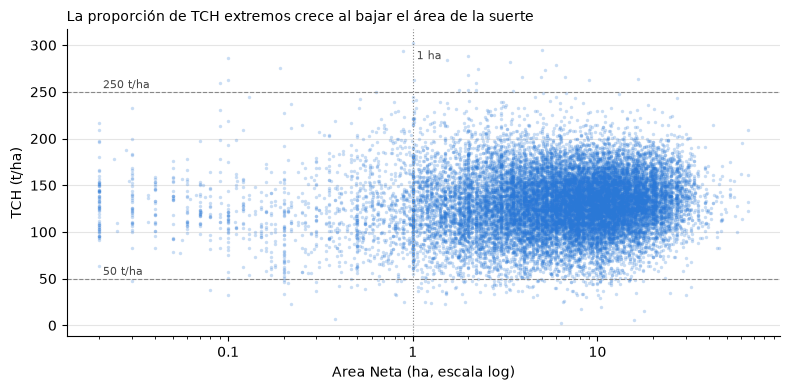

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(area.clip(lower=0.02), tch, s=6, alpha=0.25, color=AZUL, linewidths=0)
for y, txt in [(50, "50 t/ha"), (250, "250 t/ha")]:
    ax.axhline(y, color="#888", lw=0.8, ls="--")
    ax.text(0.021, y + 4, txt, fontsize=8, color="#444")
ax.axvline(1, color="#888", lw=0.8, ls=":")
ax.text(1.05, 285, "1 ha", fontsize=8, color="#444")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Area Neta (ha, escala log)")
ax.set_ylabel("TCH (t/ha)")
ax.set_title("La proporción de TCH extremos crece al bajar el área de la suerte", fontsize=10, loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_reg_tch_vs_area.png", dpi=150)
plt.show()

**Conclusión 8.3**
- **180–250 t/ha (1 196 filas, 45 orgánicas):** RN lo da como normal → **conservar**. Ninguna suerte orgánica supera 250.
- **> 250 t/ha (25 filas, máx. 302):** RN dice que "amerita revisión". 12 de las 25 están en suertes ≤ 2 ha, donde un error
  pequeño en el área (el denominador del TCH) infla el cociente. La tasa de extremos sube de forma sistemática a medida que
  baja el área (0.5% en > 5 ha frente a 2.5% en ≤ 0.5 ha).
- **< 50 t/ha (140 filas):** el perfil **no** coincide con el de la semilla excluida (semilla: edad mediana 9.1 meses;
  TCH < 50 comercial: 12.2 meses, edad normal). La hipótesis RN de "semilla mal registrada" no se puede confirmar fila por
  fila. 84 de las 140 están en suertes ≤ 5 ha.
- **Decisión (aprobada):** como es el **target**, solo se elimina lo que es probable error de medición:
  1. TCH < 50 o > 250 **con `Area Neta` ≤ 1 ha** → error del denominador → **eliminar del entrenamiento** (29 filas).
  2. El resto de los < 50 y > 250 (136 filas) → **conservar** como evento real (siniestro, cosecha parcial, alta
     productividad puntual) y documentarlo. Son los lotes que el Ingenio necesita detectar. Se revisan sus residuos;
     el MAE (ya incluido en las métricas) se reporta junto al RMSE porque el RMSE es más sensible a estas colas.
  - Sensibilidad a reportar: aplicar la regla RN literal (eliminar todo < 50 y > 250) y comparar las métricas.
  - La regla de 1 ha es un umbral fijo de negocio, no un estadístico, así que se puede aplicar antes del split sin leakage.

### 8.4 %Sac.Caña (target)

RN no define un rango de outliers para sacarosa; se contrasta con límites físicos y con variables de contexto.
`Tipo Quema` y `Vejez` se usan **solo como diagnóstico** (son leakage y no entran al modelo).

In [24]:
sac = df["%Sac.Caña"]
print(f"Rango: {sac.min():.2f}–{sac.max():.2f} | ceros: {(sac == 0).sum()} | NaN: {sac.isna().sum()}")
cola = pd.cut(sac, [0, 9, 16, 100], labels=["< 9", "9–16", "> 16"])
display(pd.crosstab(cola, df["Tipo Quema"], margins=True))
pre = df["Sac.Caña Precosecha"].where(lambda s: s > 0)
df.groupby(cola, observed=True).agg(n=("TCH", "size"), vejez_mediana=("Vejez", "median"),
                                    edad_mediana=("Edad Ult Cos", "median"),
                                    precosecha_mediana=("Sac.Caña Precosecha", lambda s: s[s > 0].median())).round(2)

Rango: 7.09–18.40 | ceros: 0 | NaN: 156


Tipo Quema,NO DEF.,Q.ACCIDENTAL,Q.PROGRAMADA,VERDE,All
%Sac.Caña,,,,,
< 9,8,45,3,48,104
9–16,503,2404,1532,16015,20454
> 16,1,1,0,17,19
All,512,2450,1535,16080,20577


,n,vejez_mediana,edad_mediana,precosecha_mediana
%Sac.Caña,,,,
< 9,104,10.10,11.46,16.72
9–16,20454,2.72,12.68,17.07
> 16,19,5.00,15.00,18.78


In [25]:
print("Año-mes de los registros > 16:", df.loc[sac > 16, "Período"].value_counts().sort_index().to_dict())

Año-mes de los registros > 16: {201901: 1, 201909: 1, 202002: 1, 202010: 1, 202011: 1, 202108: 1, 202109: 1, 202110: 5, 202111: 2, 202112: 1, 202208: 1, 202307: 2, 202308: 1}


**Conclusión 8.4**
- No hay ceros ni valores imposibles. El rango es 7.1–18.4 (156 NaN, que ya se eliminan por ser target, §6).
- **Cola baja (< 9, 104 filas):** `Q.ACCIDENTAL` representa el 43% de esta cola, frente a ~12% en la población, y la `Vejez` mediana
  es de 10.1 h frente a 2.7 h. La precosecha de esas suertes era normal (mediana 16.7), así que **la sacarosa se perdió después del
  corte**: es deterioro poscorte por quema accidental y espera → **evento real** → **conservar**.
- **Cola alta (> 16, 19 filas):** casi todas en caña verde, edad mediana de 15 meses, 10 de ellas entre ago y dic de 2021. Su precosecha
  (mediana 18.8) es coherente → **variabilidad real** → **conservar**.
- **Decisión (aprobada):** no eliminar ni transformar. Que la cola baja dependa de `Vejez` (que no está disponible antes de
  cosechar) es una **limitación**: el modelo no la va a poder anticipar, y conviene decirlo al interpretar los residuos.

### 8.5 Lluvias (criterio de escala fijado en §7)

La regla RN *"180–300 normal, ~1000 atípico genuino"* se aplica a la **escala trimestral** (`0-3`, `3-6`, `6-9`).
`2 Meses Ant.` es de ~2 meses (más estricta), `9 -FC` se evalúa en mm/mes y `Lluvias Ciclo` es solo descriptiva.
Se usan solo las filas con dato (0 = sin dato, §3).

In [26]:
TRIM = ["Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve"]
display(pd.DataFrame({c: escala(df[c]) for c in TRIM + [LLUVIAS_VENTANA[0]]}).T.round(1))
alta = (df[TRIM] >= 900).any(axis=1)
print(f"Filas con alguna ventana trimestral ≥ 900 mm: {alta.sum()}")
print("  por año:", anio[alta].value_counts().sort_index().to_dict(), "| por zona:", df.loc[alta, "Zona"].value_counts().to_dict())
print("  por hacienda:", df.loc[alta, "Hacienda"].value_counts().to_dict())

,p25,mediana,p75,p95,%_en_180_300,%_>=900
Lluvias 0 -3,118.0,204.0,299.0,441.0,32.7,0.1
Lluvias tres a seis,120.0,195.0,288.0,451.0,33.0,0.1
Lluvias seis a nueve,119.0,197.0,287.0,438.0,33.1,0.1
Lluvias (2 Meses Ant.),76.0,126.5,193.0,309.0,23.0,0.0


Filas con alguna ventana trimestral ≥ 900 mm: 28
  por año: {2017: 16, 2018: 12} | por zona: {'IP01': 21, 'IP06': 7}
  por hacienda: {80121: 19, 80130: 7, 80485: 2}


In [27]:
# ¿El valor ≥ 900 es propio de la hacienda o de toda la zona en ese período? Se compara con la mediana de las
# OTRAS haciendas de la misma Zona y Período (solo filas con dato).
filas = []
for c in TRIM:
    for i in df.index[df[c] >= 900]:
        z, p, h_ = df.at[i, "Zona"], df.at[i, "Período"], df.at[i, "Hacienda"]
        vec = df.loc[(df["Zona"] == z) & (df["Período"] == p) & (df["Hacienda"] != h_) & (df[c] > 0), c]
        filas.append({"ventana": c, "Hacienda": h_, "Período": p, "Zona": z, "valor": df.at[i, c],
                      "mediana_vecinos": vec.median(), "n_vecinos": len(vec)})
vecinos = pd.DataFrame(filas).drop_duplicates()
vecinos["razon"] = (vecinos["valor"] / vecinos["mediana_vecinos"]).round(1)
print("Razón valor / mediana de vecinos:", vecinos["razon"].describe()[["min", "50%", "max"]].to_dict())
vecinos.sort_values(["Hacienda", "Período"]).head(15)

Razón valor / mediana de vecinos: {'min': 1.2, '50%': 2.7, 'max': 22.8}


,ventana,Hacienda,Período,Zona,valor,mediana_vecinos,n_vecinos,razon
23,Lluvias seis a nueve,80121,201704,IP01,967.0,352.5,2,2.7
26,Lluvias seis a nueve,80121,201705,IP01,1041.0,281.0,13,3.7
11,Lluvias tres a seis,80121,201708,IP01,1050.0,565.5,2,1.9
12,Lluvias tres a seis,80121,201708,IP01,1028.0,565.5,2,1.8
13,Lluvias tres a seis,80121,201709,IP01,912.0,44.0,3,20.7
14,Lluvias tres a seis,80121,201709,IP01,1005.0,44.0,3,22.8
16,Lluvias tres a seis,80121,201710,IP01,901.0,425.0,10,2.1
27,Lluvias seis a nueve,80121,201710,IP01,996.0,368.0,10,2.7
0,Lluvias 0 -3,80121,201711,IP01,910.0,378.0,4,2.4
1,Lluvias 0 -3,80121,201711,IP01,1005.0,378.0,4,2.7


In [28]:
# Ciclo anualizado (mm/año): ¿2017–2018 fueron lluviosos en toda la zona, o es la hacienda?
anual = (df[LL_CICLO].where(df[LL_CICLO] > 0) / df["Edad Ult Cos"] * 12)
display(anual.groupby([anio, df["Zona"]]).median().unstack().round(0))
m1718 = anio.isin([2017, 2018])
print("Ciclo anualizado de las 28 filas ≥ 900:", anual[alta].describe()[["min", "50%", "max"]].round(0).to_dict())
print("80121 en 2017–18, resto de sus filas:", anual[(df["Hacienda"] == 80121) & m1718 & ~alta].median().round(0))
print("IP01 en 2017–18, otras haciendas (p50 / p99):",
      anual[(df["Zona"] == "IP01") & m1718 & (df["Hacienda"] != 80121)].quantile([.5, .99]).round(0).to_dict())
print("Máximo trimestral fuera de esas 28 filas:", df.loc[~alta, TRIM].max().to_dict())

Zona,IC07,IP01,IP02,IP03,IP05,IP06,ip05
Período,,,,,,,
2017,NaN,1415.0,796.0,1032.0,856.0,1136.0,NaN
2018,NaN,1342.0,954.0,994.0,837.0,999.0,NaN
2019,NaN,812.0,302.0,779.0,581.0,713.0,NaN
2020,NaN,647.0,272.0,497.0,442.0,555.0,NaN
2021,NaN,864.0,506.0,605.0,600.0,644.0,NaN
2022,NaN,1274.0,769.0,752.0,563.0,867.0,NaN
2023,NaN,1113.0,754.0,865.0,605.0,801.0,NaN
2024,NaN,873.0,631.0,665.0,606.0,676.0,NaN


Ciclo anualizado de las 28 filas ≥ 900: {'min': 1949.0, '50%': 2505.0, 'max': 2881.0}
80121 en 2017–18, resto de sus filas: 1770.0
IP01 en 2017–18, otras haciendas (p50 / p99): {0.5: 1291.0, 0.99: 2021.0}
Máximo trimestral fuera de esas 28 filas: {'Lluvias 0 -3': 852.0, 'Lluvias tres a seis': 895.0, 'Lluvias seis a nueve': 837.0}


In [29]:
# 9-FC: duración variable (Edad − 9 meses) → tasa mm/mes
fc = df["Luvias 9 -FC"]
meses_fc = df["Edad Ult Cos"] - 9
incoh = (meses_fc <= 0) & (fc > 0)
print(f"9-FC > 0 con Edad < 9 meses (ventana inexistente): {incoh.sum()} | valores: {fc[incoh].describe()[['50%', 'max']].to_dict()}")
ok = (fc > 0) & (meses_fc >= 1)
tasa = fc[ok] / meses_fc[ok]
print("9-FC mm/mes (ventanas ≥ 1 mes):", tasa.describe()[["25%", "50%", "75%", "max"]].round(0).to_dict())
print(f"Tasa > 300 mm/mes (≈ 900 mm/trimestre, misma regla RN): {(tasa > 300).sum()} filas | "
      f"haciendas: {df.loc[tasa[tasa > 300].index, 'Hacienda'].value_counts().to_dict()}")
print("Tasa de las ventanas trimestrales (mm/mes, mediana):", {c: round(df.loc[df[c] > 0, c].median() / 3) for c in TRIM})

9-FC > 0 con Edad < 9 meses (ventana inexistente): 23 | valores: {'50%': 8.0, 'max': 50.0}


9-FC mm/mes (ventanas ≥ 1 mes): {'25%': 44.0, '50%': 68.0, '75%': 95.0, 'max': 457.0}
Tasa > 300 mm/mes (≈ 900 mm/trimestre, misma regla RN): 6 filas | haciendas: {80121: 4, 80130: 2}
Tasa de las ventanas trimestrales (mm/mes, mediana): {'Lluvias 0 -3': 68, 'Lluvias tres a seis': 65, 'Lluvias seis a nueve': 66}


**Conclusión 8.5**
- **Ventanas trimestrales:** la mayoría está en el rango RN o cerca (mediana ~200, p75 ~290, p95 ~445). Hay **28 filas** con
  alguna ventana ≥ 900 mm, **todas de 2017–2018 y de solo 3 haciendas** (80121: 19, 80130: 7, 80485: 2). Las ventanas suman
  el ciclo exacto, así que no son un error de tipeo aislado.
- **¿Evento real o pluviómetro?** La evidencia es mixta:
  - 2017–18 fue lluvioso en toda la zona (IP01 ~1 300–1 400 mm/año frente a ~650–860 en 2019–21).
  - La hacienda 80121 es más lluviosa que su zona **de forma sistemática** (mediana de 1 770 mm/año en sus otras filas, frente a 1 291 en el
    resto de IP01). Esto es compatible con un microclima de piedemonte o con un pluviómetro con sesgo.
  - Las 28 filas llegan a ~2 500 mm/año, por encima del p99 de la zona (~2 000). Frente a otras haciendas del mismo período,
    la razón es ~2.7× (con pocos vecinos, así que es ruidoso).
  - Sin Cenicaña en esos años, **no se puede decidir entre error y evento**. RN lo clasifica como *"atípico genuino"*.
- *Decisión:* **conservar la fila y recortar** las ventanas trimestrales a un **tope fijo de 900 mm** (el umbral RN,
  no un percentil del dataset, así que no hay leakage). Se mantiene la señal de "trimestre muy lluvioso" y se quita
  palanca al modelo lineal. Afecta solo a esas 28 filas: fuera de ellas, el máximo es 895. No se pasa a NaN porque eso
  borraría un dato que puede ser real.
- **Resto de la cola (~450–900):** coincide con años lluviosos en toda la zona → **variabilidad natural** → **conservar**. En el modelo
  lineal se aplica `log1p` a las ventanas (no tiene parámetros, así que no filtra información). Los árboles no lo necesitan.
- **`9 -FC`:** la tasa mediana (68 mm/mes) coincide con la de las trimestrales (65–68). Hay 6 filas > 300 mm/mes (≈ 900/trimestre),
  de las mismas haciendas 80121 y 80130 → mismo tratamiento: tope de 300 mm/mes × meses de la ventana.
  **23 filas con `9 -FC` > 0 y Edad < 9 meses** (valores pequeños, mediana 8 mm): la ventana no existe → incoherencia
  interna → NaN.
- **`Lluvias Ciclo`:** la regla RN no aplica (§7) y la variable queda fuera del modelo lineal (VIF) → sin decisión de outlier.

### 8.6 Resumen de decisiones de outliers (se aplican en el Pipeline)

| Variable | Casos | Tipo | Contraste RN | Decisión |
|---|---|---|---|---|
| `Semanas mad.` < 0 | 8 | Error de fecha (madurante aplicado después del corte) | Imposible físicamente | → NaN, `madurada = 1`, mediana de train |
| `Semanas mad.` > duración del ciclo | 2 (60.1, 90.3) | Error de fecha | Imposible | → NaN (igual que arriba) |
| `Semanas mad.` > 20 (incl. 96.3) | ~440 | Evento operativo real (cosecha postergada 2021–23) | Coherente con el efecto del momento de maduración sobre la sacarosa | **Conservar**; forma no lineal en el modelo lineal |
| Producto con dosis 0 | 24 | Error de captura de la dosis | RN: producto informado = aplicado | Dosis → NaN, mediana del producto (train) |
| Sin producto con dosis > 0 | 3 | Falta capturar el producto | — | `Producto = "Desconocido"`, `madurada = 1` |
| `Producto` (acentos) | 10 367 | Duplicado de categoría | — | Normalizar texto |
| TCH 180–250 | 1 196 | Variabilidad natural | RN: normal | **Conservar** |
| TCH < 50 / > 250 con área ≤ 1 ha | 29 | Error del denominador | RN: atípico | **Eliminar** del entrenamiento |
| TCH < 50 / > 250, resto | 136 | Evento real, sin evidencia de semilla | RN: atípico | **Conservar** + sensibilidad con la regla RN literal |
| %Sac.Caña < 9 / > 16 | 104 / 19 | Evento real (deterioro poscorte / caña madura) | Sin rango RN | **Conservar** |
| Lluvias trimestrales ≥ 900 | 28 filas, 3 haciendas, 2017–18 | Indeterminado (microclima o pluviómetro) | RN: ~1000 = atípico genuino | **Recortar** a 900 mm (tope fijo) |
| `9 -FC` > 300 mm/mes | 6 | Ídem | Ídem, en mm/mes | Recortar a 300 mm/mes × meses |
| Lluvias 450–900 | cola | Variabilidad natural (años lluviosos) | Dentro de ×3 del rango RN | **Conservar** + `log1p` (lineal) |
| `9 -FC` con Edad < 9 | 23 | Incoherencia interna | — | → NaN |

In [30]:
assert len(df) == 20_733  # §8 no modifica df